# DSCI 552 Homework 6

**Name:** Shirley (Xue) Feng  
**GitHub Username:** snowxxxue  
**USC ID:** 7145149057

## Question 1: Tree-Based Methods

### Part (a)

In [1]:
import pandas as pd

train = pd.read_csv(
    "Data/aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test = pd.read_csv(
    "Data/aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

print("Training set:", train.shape)
print("Test set:", test.shape)

Training set: (60000, 171)
Test set: (16000, 171)


### Part (b): Data Preparation

#### (i): Missing-Value Imputation

Common ways to handle missing values include deleting rows or columns with missing entries, replacing missing values with a column statistic such as the mean or median, using KNN imputation, and estimating missing values from other features with an iterative model. Since this dataset has many numeric features and dropping rows could remove useful observations, I use median imputation. The median is less sensitive to extreme values than the mean. I apply it to the features in the following data preparation steps.

Reference: [scikit-learn, Imputation of missing values](https://scikit-learn.org/stable/modules/impute.html)

#### (ii): Coefficients of Variation


In [2]:
# Separate the predictors from the response
X_train_raw = train.drop(columns="class")
X_test_raw = test.drop(columns="class")

# Impute missing values with each dataset's column medians
X_train = X_train_raw.fillna(X_train_raw.median())
X_test = X_test_raw.fillna(X_test_raw.median())

# Calculate the sample mean, sample standard deviation, and CV
feature_mean = X_train.mean()
feature_sd = X_train.std(ddof=1)
cv = (feature_sd / feature_mean).where(feature_mean != 0)

cv_table = pd.DataFrame({
    "Mean": feature_mean,
    "Sample SD": feature_sd,
    "CV": cv
}).sort_values("CV", ascending=False)

display(cv_table)

,Mean,Sample SD,CV
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
...,...,...,...
bo_000,3.258947e+05,2.582334e+05,0.792383
bp_000,3.420739e+05,2.577156e+05,0.753392
bq_000,3.573117e+05,2.567407e+05,0.718534
br_000,3.713041e+05,2.558701e+05,0.689112


#### (iii): Correlation Matrix

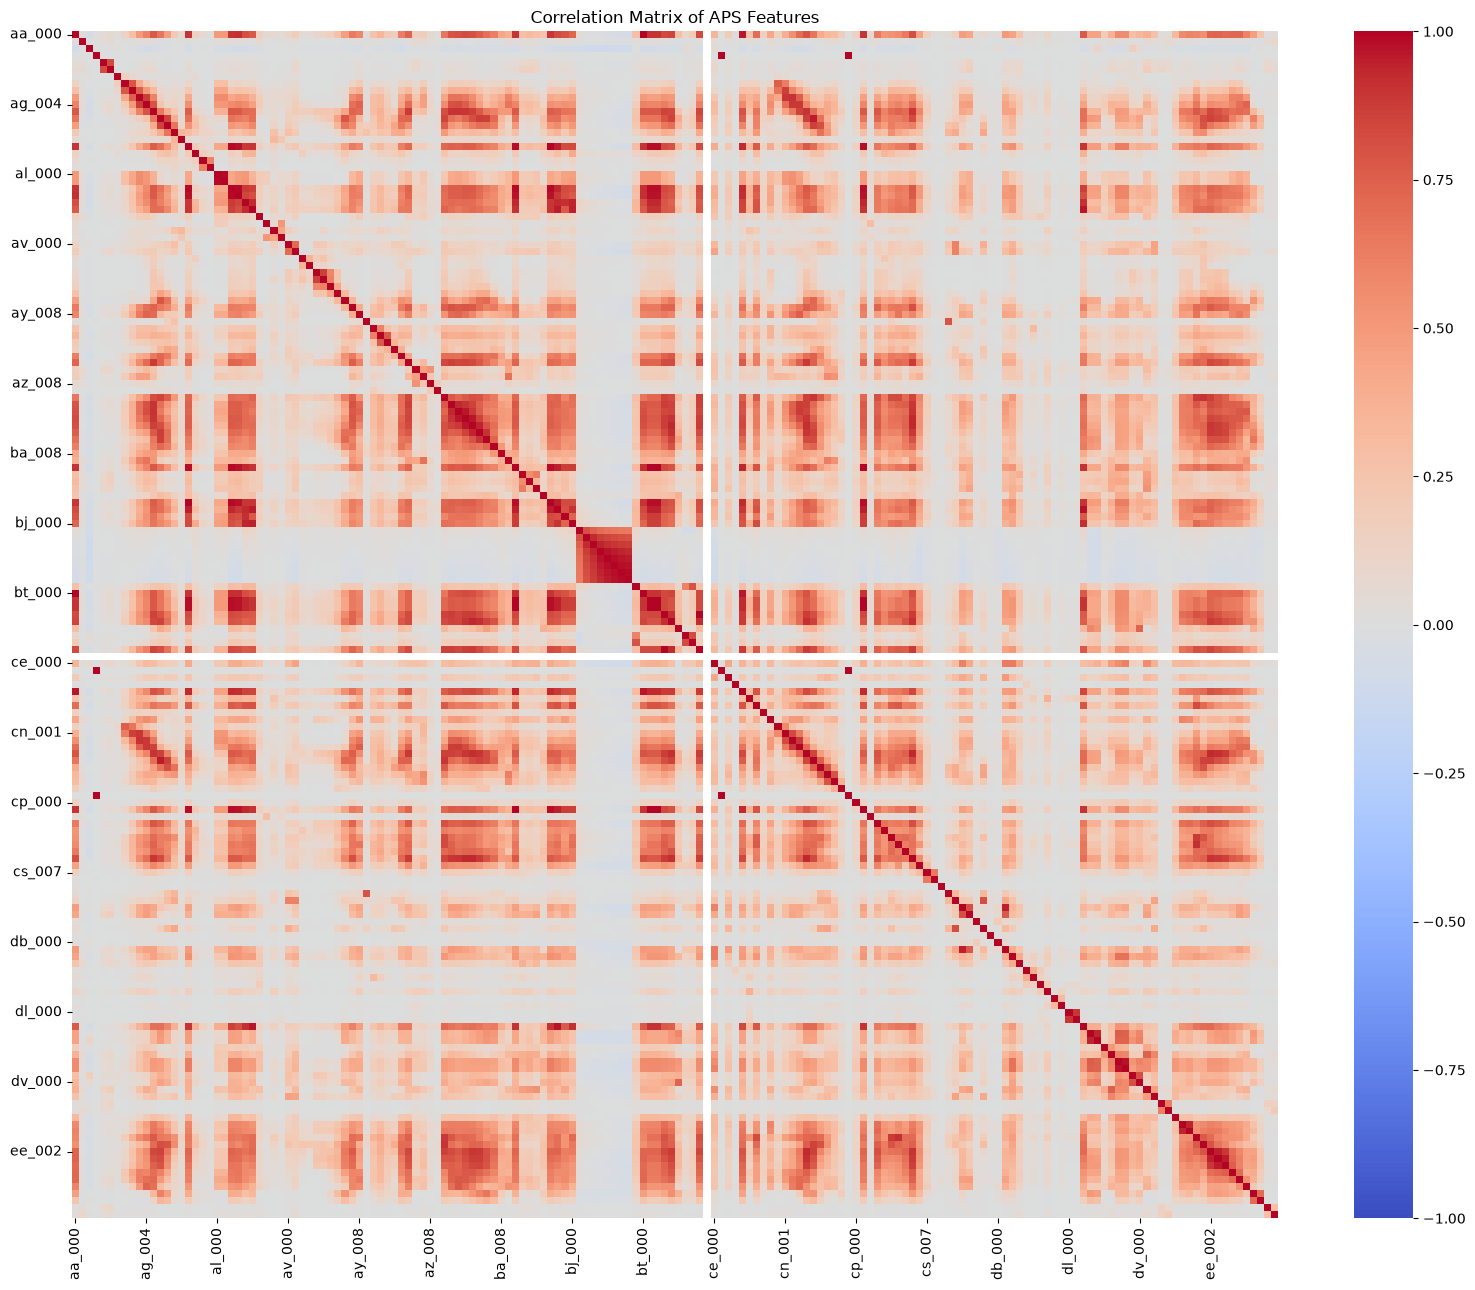

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = X_train.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=10,
    yticklabels=10
)

plt.title("Correlation Matrix of APS Features")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### (iv): Feature Plots

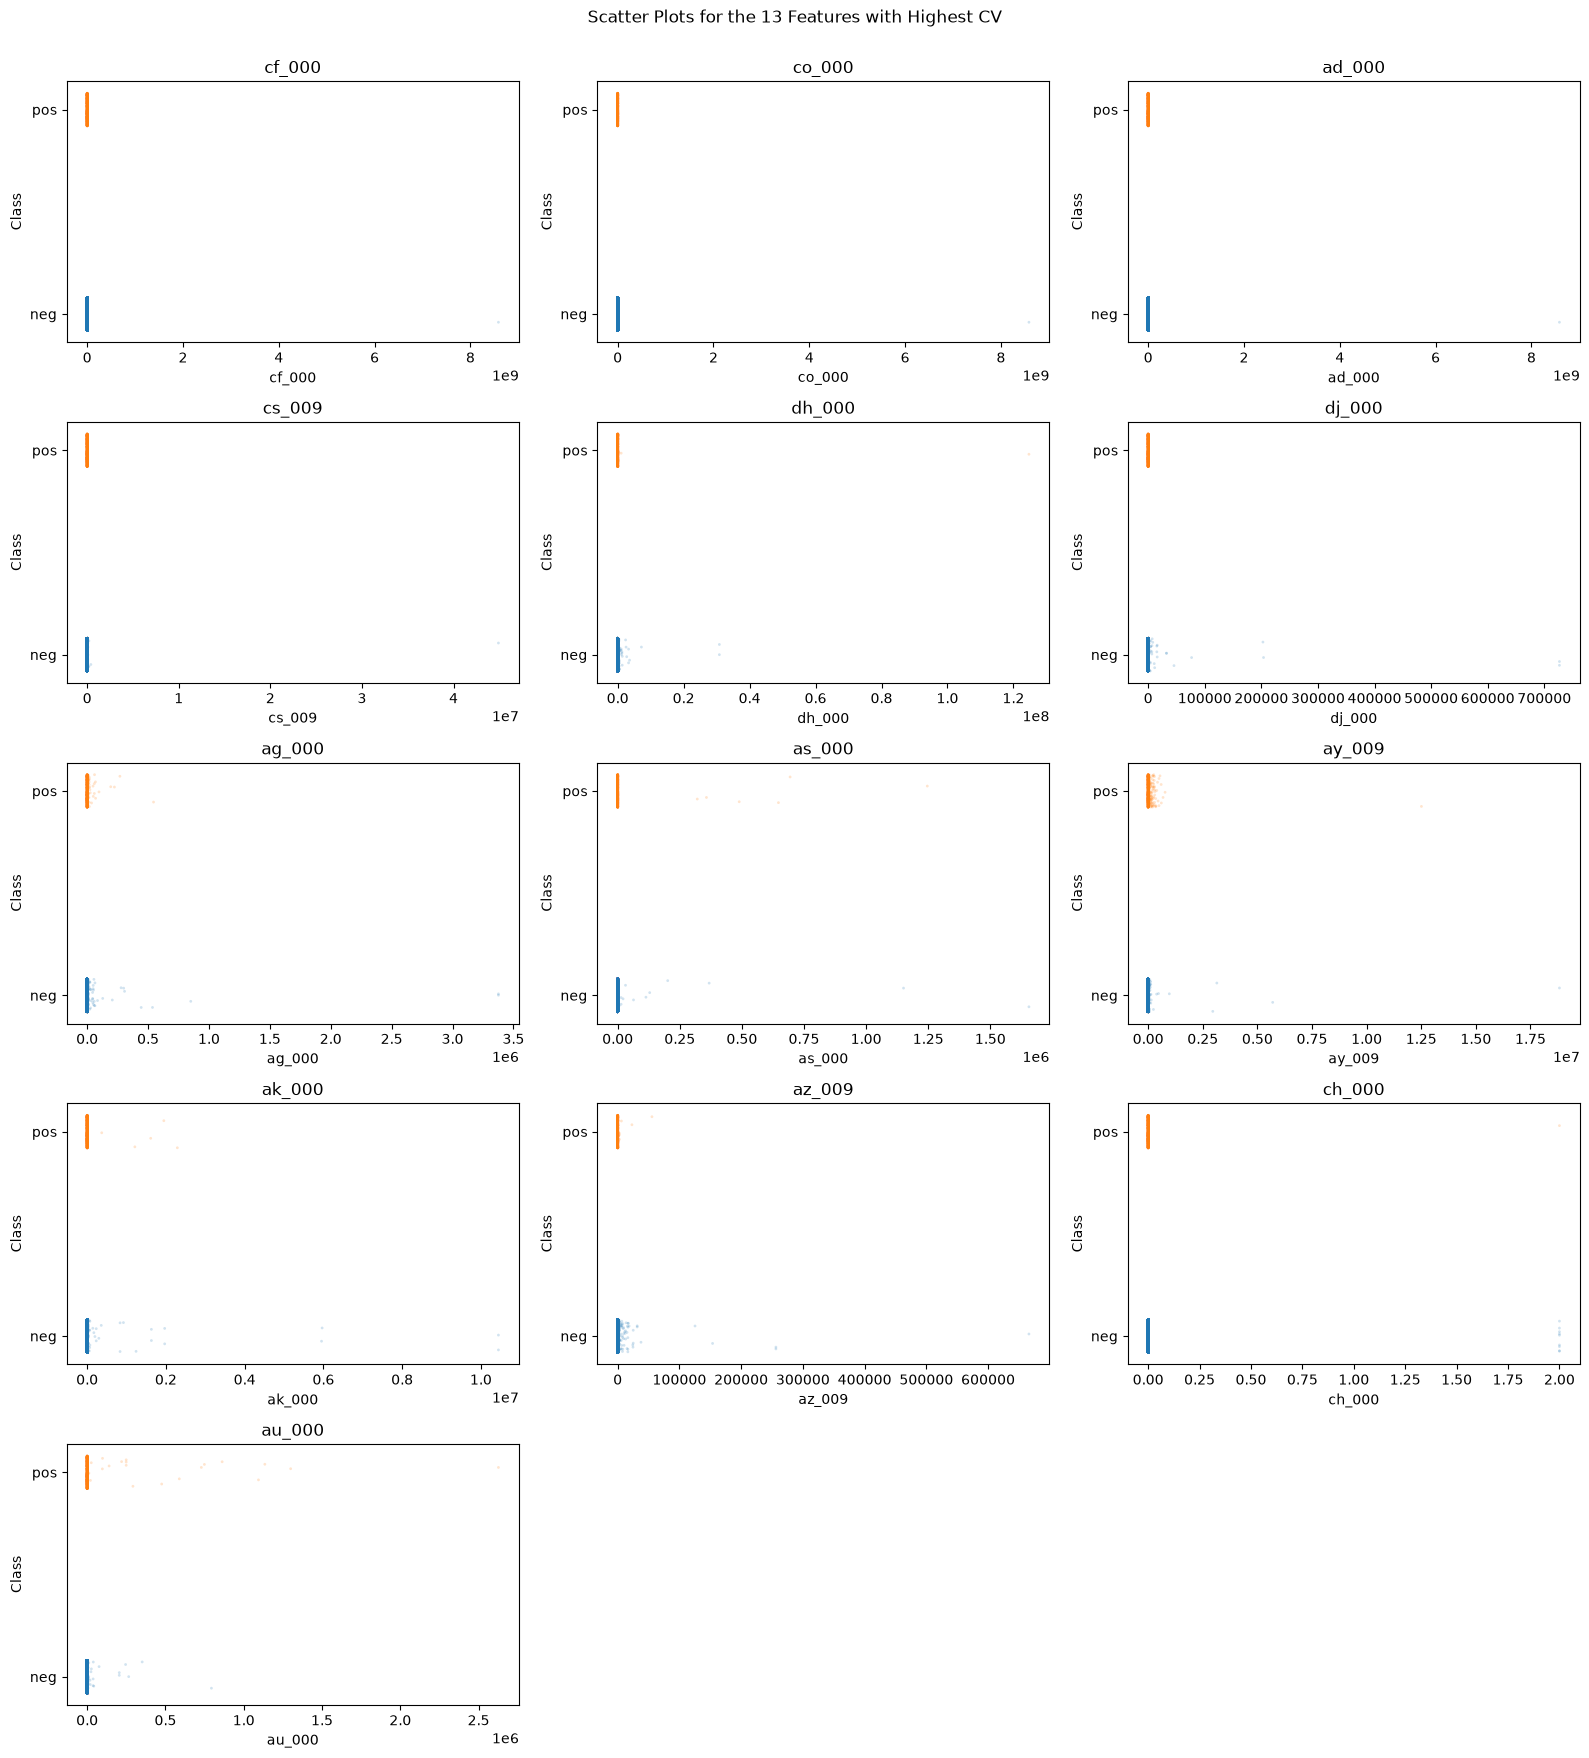

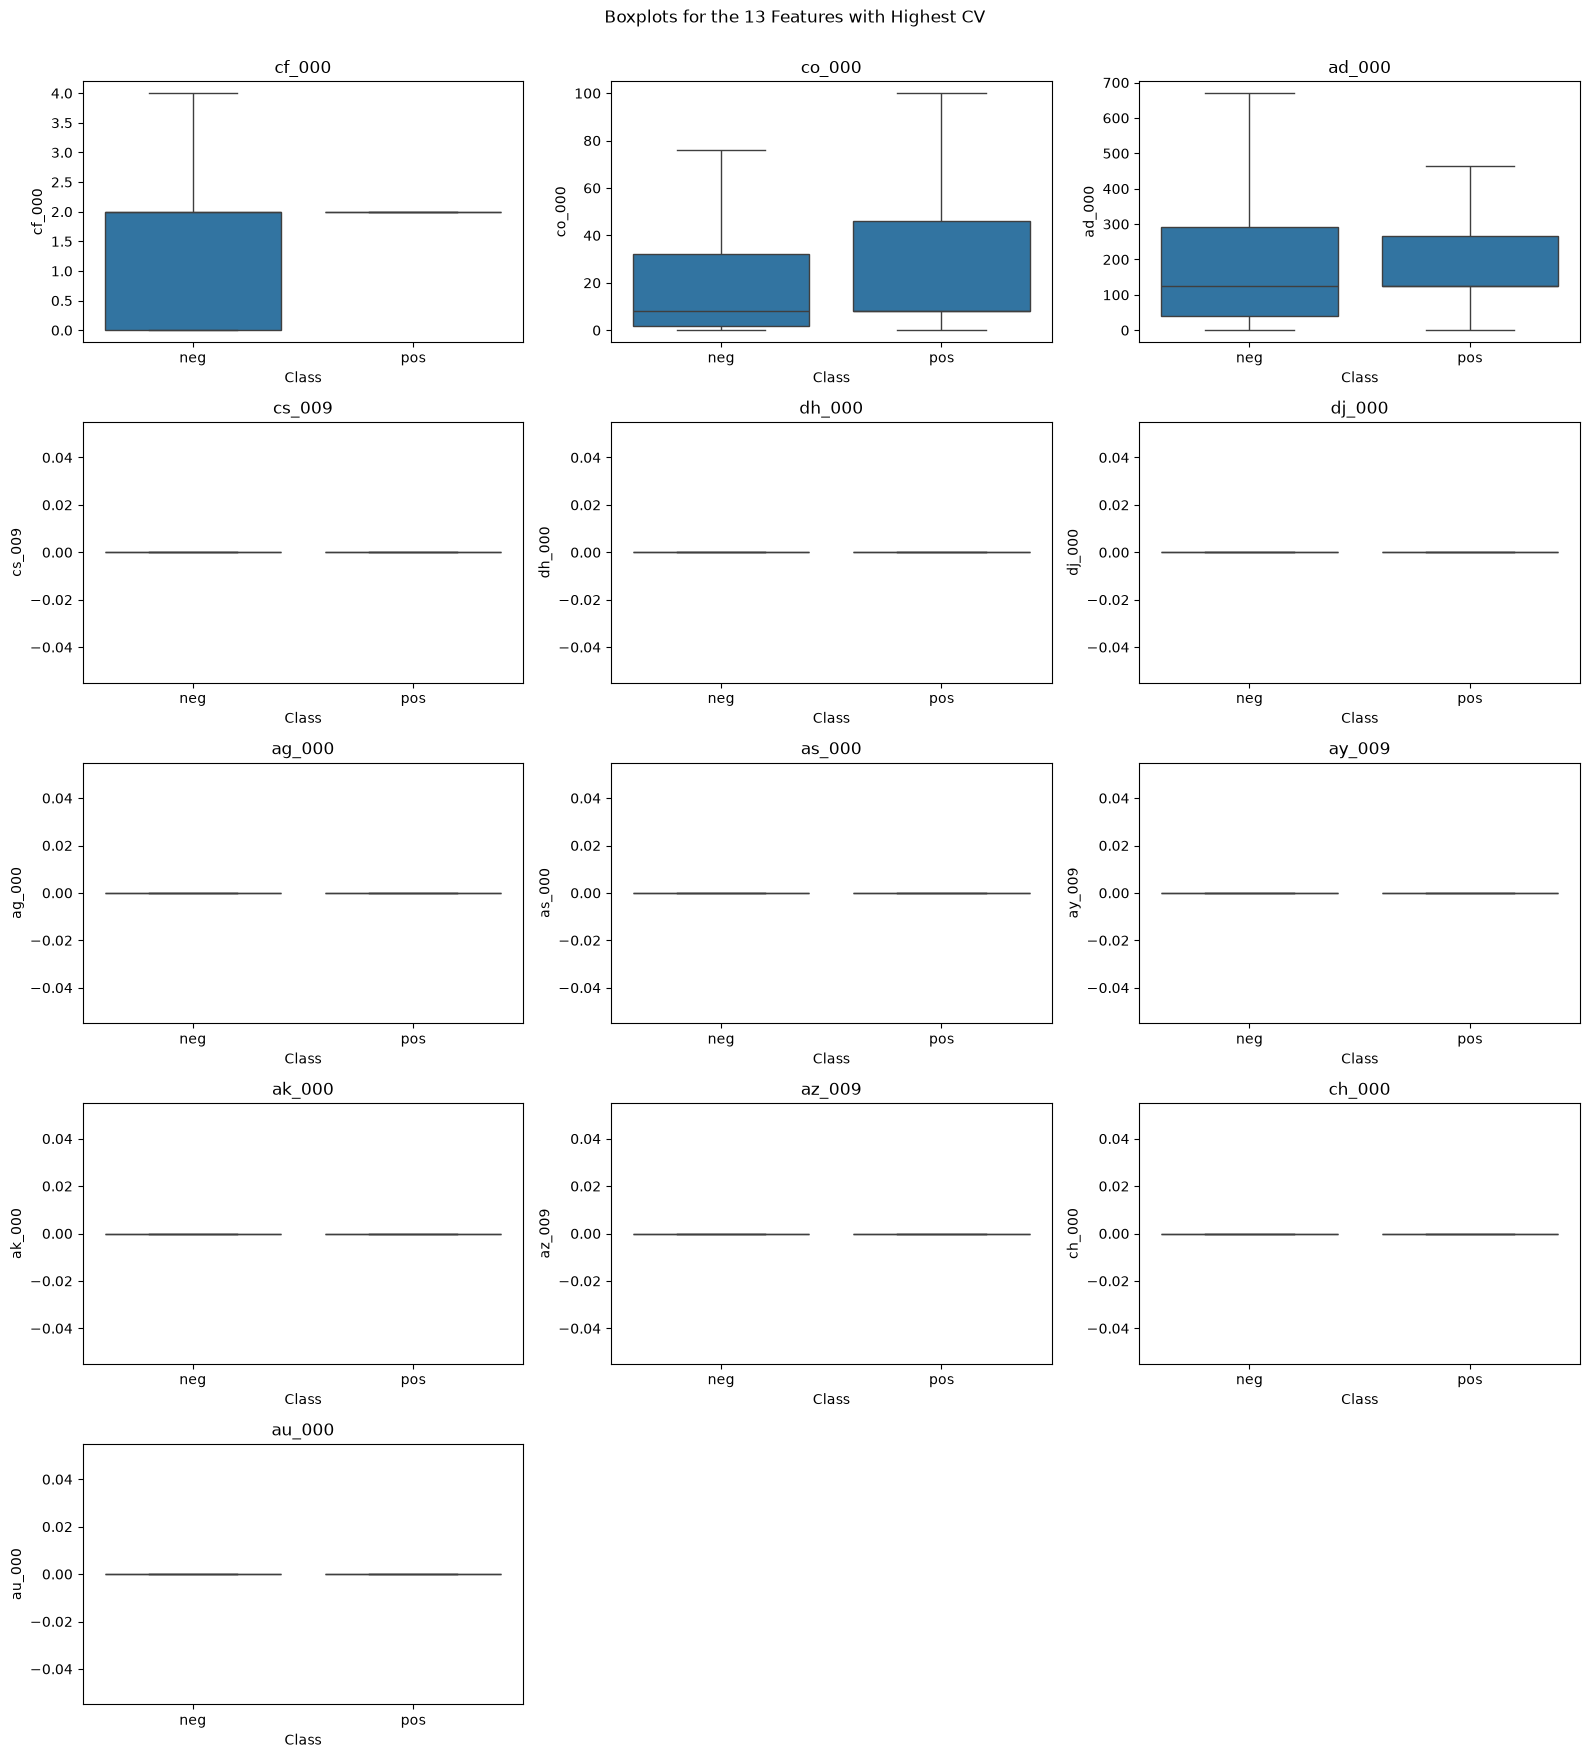

In [4]:
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

n_top = math.floor(np.sqrt(X_train.shape[1]))
top_features = cv_table.head(n_top).index.tolist()

y_numeric = train.loc[X_train.index, "class"].map({"neg": 0, "pos": 1})
point_colors = y_numeric.map({0: "tab:blue", 1: "tab:orange"})
rng = np.random.default_rng(1)
jitter = rng.uniform(-0.08, 0.08, size=len(y_numeric))

n_cols = 3
n_rows = math.ceil(len(top_features) / n_cols)

# Scatter plots of each feature against the class label
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
axes = np.array(axes).reshape(-1)

for feature, ax in zip(top_features, axes):
    ax.scatter(
        X_train[feature],
        y_numeric + jitter,
        c=point_colors,
        s=4,
        alpha=0.2,
        linewidths=0,
        rasterized=True
    )
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Class")
    ax.set_yticks([0, 1], labels=["neg", "pos"])

for ax in axes[len(top_features):]:
    ax.set_visible(False)

fig.suptitle("Scatter Plots for the 13 Features with Highest CV", y=1.002)
plt.tight_layout()
plt.show()

# Boxplots of each feature by class
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
axes = np.array(axes).reshape(-1)

for feature, ax in zip(top_features, axes):
    sns.boxplot(
        data=train.assign(**{feature: X_train[feature]}),
        x="class",
        y=feature,
        order=["neg", "pos"],
        showfliers=False,
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Class")
    ax.set_ylabel(feature)

for ax in axes[len(top_features):]:
    ax.set_visible(False)

fig.suptitle("Boxplots for the 13 Features with Highest CV", y=1.002)
plt.tight_layout()
plt.show()

The plots show that several features are highly right-skewed, with many values near zero and a few very large values. Some feature distributions differ between the two classes, but several boxplots show substantial overlap or are concentrated near zero. These plots alone do not establish statistical significance or predictive importance.

#### (v): Class Counts and Class Imbalance

In [5]:
class_counts = train["class"].value_counts()

positive_count = class_counts["pos"]
negative_count = class_counts["neg"]
positive_percentage = positive_count / len(train) * 100

print("Positive samples:", positive_count)
print("Negative samples:", negative_count)
print(f"Positive class percentage: {positive_percentage:.2f}%")
print(f"Negative-to-positive ratio: {negative_count / positive_count:.0f}:1")

Positive samples: 1000
Negative samples: 59000
Positive class percentage: 1.67%
Negative-to-positive ratio: 59:1


### Part (c): Random Forest Without Class-Imbalance Compensation

Training confusion matrix (rows = true, columns = predicted):
[[59000     0]
 [    0  1000]]
Test confusion matrix (rows = true, columns = predicted):
[[15609    16]
 [  105   270]]
Training misclassification rate: 0.0000
Test misclassification rate: 0.0076
OOB error estimate: 0.0060
Training AUC: 1.0000
Test AUC: 0.9942


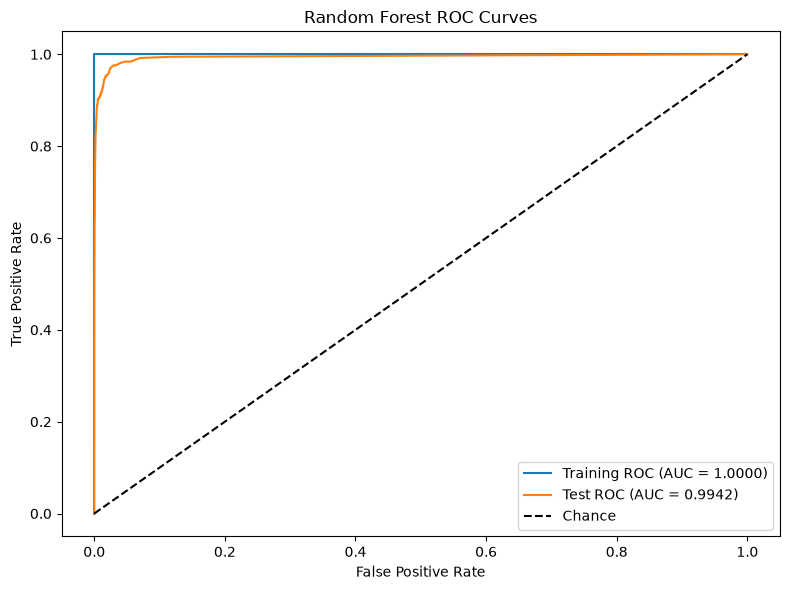

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

y_train = train["class"]
y_test = test["class"]

rf = RandomForestClassifier(
    n_estimators=200,
    bootstrap=True,
    oob_score=True,
    class_weight=None,
    random_state=1,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# Class predictions
train_pred = rf.predict(X_train)
test_pred = rf.predict(X_test)

# Positive-class probabilities for ROC and AUC
positive_class_index = list(rf.classes_).index("pos")
train_prob = rf.predict_proba(X_train)[:, positive_class_index]
test_prob = rf.predict_proba(X_test)[:, positive_class_index]

# Binary labels for ROC and AUC
y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)

# Confusion matrices
labels = ["neg", "pos"]

print("Training confusion matrix (rows = true, columns = predicted):")
print(confusion_matrix(y_train, train_pred, labels=labels))

print("Test confusion matrix (rows = true, columns = predicted):")
print(confusion_matrix(y_test, test_pred, labels=labels))

# Misclassification rates
train_error = np.mean(train_pred != y_train)
test_error = np.mean(test_pred != y_test)
oob_error = 1 - rf.oob_score_

print(f"Training misclassification rate: {train_error:.4f}")
print(f"Test misclassification rate: {test_error:.4f}")
print(f"OOB error estimate: {oob_error:.4f}")

# ROC curves and AUC
fpr_train, tpr_train, _ = roc_curve(y_train_binary, train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test_binary, test_prob)

train_auc = roc_auc_score(y_train_binary, train_prob)
test_auc = roc_auc_score(y_test_binary, test_prob)

print(f"Training AUC: {train_auc:.4f}")
print(f"Test AUC: {test_auc:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, label=f"Training ROC (AUC = {train_auc:.4f})")
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

The random forest classified all training observations correctly, with a training error of 0 and an AUC of 1.0000. On the test set, it correctly classified 15,609 negative cases and 270 positive cases, with 16 false positives and 105 false negatives. The test error was 0.76%, and the test AUC was 0.9942. The OOB error was 0.60%, which is close to the test error. Although the overall test performance was strong, the model missed 105 of the 375 positive cases at the default classification threshold. Therefore, the low test error alone does not show how well the model detects the minority class.

### Part (d): Random Forest With Class-Imbalance Compensation

Training confusion matrix (rows = true, columns = predicted):
[[59000     0]
 [    0  1000]]
Test confusion matrix (rows = true, columns = predicted):
[[15612    13]
 [  156   219]]
Training misclassification rate: 0.0000
Test misclassification rate: 0.0106
OOB error estimate: 0.0076
Training AUC: 1.0000
Test AUC: 0.9934


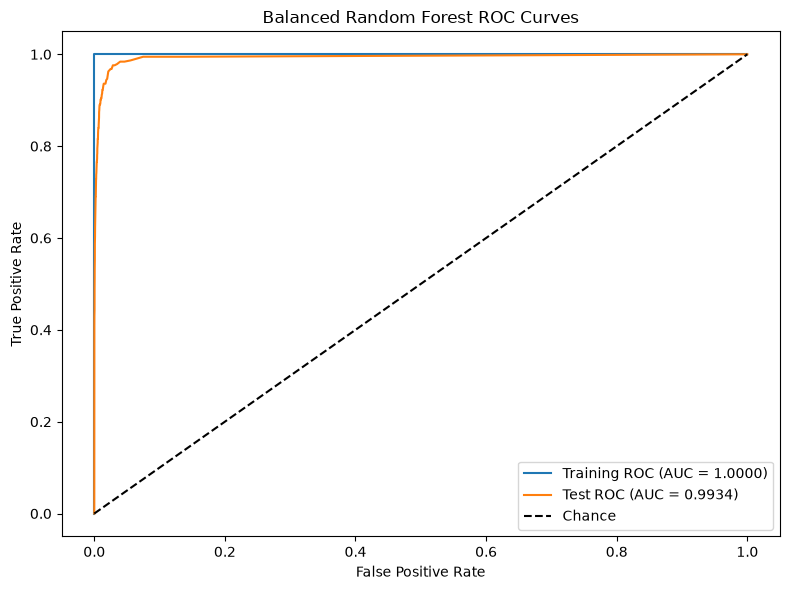

,No compensation,Balanced subsample
Training error,0.000000,0.000000
Test error,0.007562,0.010563
OOB error,0.006033,0.007617
Training AUC,1.000000,1.000000
Test AUC,0.994203,0.993396


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

rf_balanced = RandomForestClassifier(
    n_estimators=200,
    bootstrap=True,
    oob_score=True,
    class_weight="balanced_subsample",
    random_state=1,
    n_jobs=-1
)

rf_balanced.fit(X_train, y_train)

balanced_train_pred = rf_balanced.predict(X_train)
balanced_test_pred = rf_balanced.predict(X_test)

positive_class_index = list(rf_balanced.classes_).index("pos")
balanced_train_prob = rf_balanced.predict_proba(X_train)[:, positive_class_index]
balanced_test_prob = rf_balanced.predict_proba(X_test)[:, positive_class_index]

print("Training confusion matrix (rows = true, columns = predicted):")
print(confusion_matrix(y_train, balanced_train_pred, labels=["neg", "pos"]))

print("Test confusion matrix (rows = true, columns = predicted):")
print(confusion_matrix(y_test, balanced_test_pred, labels=["neg", "pos"]))

balanced_train_error = np.mean(balanced_train_pred != y_train)
balanced_test_error = np.mean(balanced_test_pred != y_test)
balanced_oob_error = 1 - rf_balanced.oob_score_

y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)

balanced_train_auc = roc_auc_score(y_train_binary, balanced_train_prob)
balanced_test_auc = roc_auc_score(y_test_binary, balanced_test_prob)

print(f"Training misclassification rate: {balanced_train_error:.4f}")
print(f"Test misclassification rate: {balanced_test_error:.4f}")
print(f"OOB error estimate: {balanced_oob_error:.4f}")
print(f"Training AUC: {balanced_train_auc:.4f}")
print(f"Test AUC: {balanced_test_auc:.4f}")

fpr_train_balanced, tpr_train_balanced, _ = roc_curve(
    y_train_binary, balanced_train_prob
)
fpr_test_balanced, tpr_test_balanced, _ = roc_curve(
    y_test_binary, balanced_test_prob
)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr_train_balanced,
    tpr_train_balanced,
    label=f"Training ROC (AUC = {balanced_train_auc:.4f})"
)
plt.plot(
    fpr_test_balanced,
    tpr_test_balanced,
    label=f"Test ROC (AUC = {balanced_test_auc:.4f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

comparison = pd.DataFrame(
    {
        "No compensation": [
            train_error,
            test_error,
            oob_error,
            train_auc,
            test_auc
        ],
        "Balanced subsample": [
            balanced_train_error,
            balanced_test_error,
            balanced_oob_error,
            balanced_train_auc,
            balanced_test_auc
        ]
    },
    index=[
        "Training error",
        "Test error",
        "OOB error",
        "Training AUC",
        "Test AUC"
    ]
)

display(comparison)

#### How Random Forests Address Class Imbalance

Class imbalance can be addressed by changing the class weights or by resampling the training data. In this analysis, I use `class_weight="balanced_subsample"`. This option adjusts class weights inversely according to class frequencies in each tree's bootstrap sample. As a result, the minority class has a greater influence on the weighted split criteria.

Reference: [scikit-learn RandomForestClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

Class weighting did not improve the test results in this run. The test error increased from 0.76% without compensation to 1.06% with `balanced_subsample`, while the test AUC changed slightly from 0.9942 to 0.9934. The weighted model made fewer false-positive errors (13 instead of 16), but it missed more positive cases (156 instead of 105). Its positive-class recall decreased from 72.0% to 58.4%. Thus, this class-weighting approach did not improve the detection of the minority class for this model.

### Part (e): XGBoost and Model Trees

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

y_train_xgb = (y_train == "pos").astype(int)
y_test_xgb = (y_test == "pos").astype(int)

cv_folds = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

xgb_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1,
    random_state=1,
    n_jobs=-1
)

alpha_grid = {
    "reg_alpha": [0, 0.01, 0.1, 1, 10]
}

xgb_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=alpha_grid,
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=1,
    refit=True
)

xgb_search.fit(X_train, y_train_xgb)

best_alpha = xgb_search.best_params_["reg_alpha"]
cv_error = 1 - xgb_search.best_score_

cv_results = pd.DataFrame({
    "Alpha": xgb_search.cv_results_["param_reg_alpha"].astype(float),
    "Mean CV Accuracy": xgb_search.cv_results_["mean_test_score"]
})
cv_results["Mean CV Error"] = 1 - cv_results["Mean CV Accuracy"]

print("Best alpha:", best_alpha)
print(f"Best mean CV error: {cv_error:.4f}")
display(cv_results)

Best alpha: 0.1
Best mean CV error: 0.0070


,Alpha,Mean CV Accuracy,Mean CV Error
0,0.00,0.992933,0.007067
1,0.01,0.992967,0.007033
2,0.10,0.993017,0.006983
3,1.00,0.992883,0.007117
4,10.00,0.992350,0.007650


Training confusion matrix (rows = true, columns = predicted; 0 = neg, 1 = pos):
[[58932    68]
 [  231   769]]
Test confusion matrix (rows = true, columns = predicted; 0 = neg, 1 = pos):
[[15598    27]
 [  119   256]]
Best alpha: 0.1
Five-fold CV error: 0.0070
Training misclassification rate: 0.0050
Test misclassification rate: 0.0091
Training AUC: 0.9954
Test AUC: 0.9959


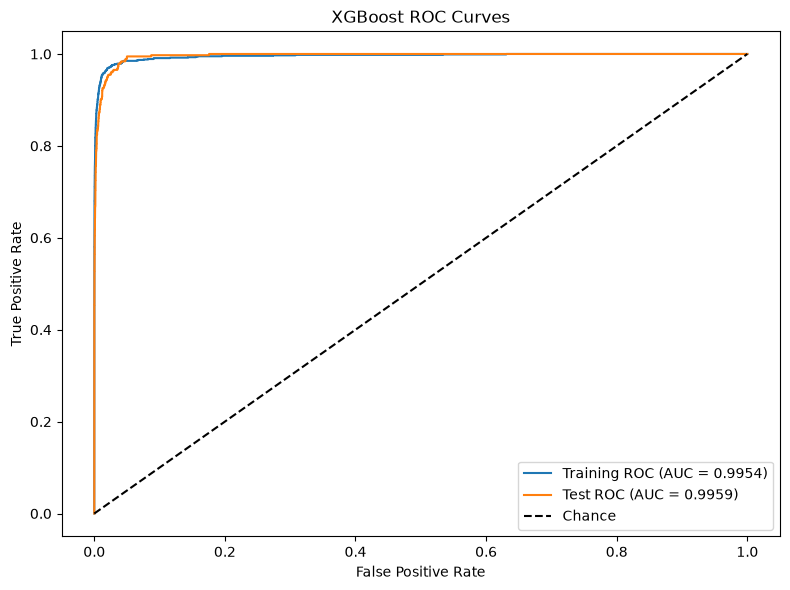

In [9]:
xgb_best = xgb_search.best_estimator_

train_pred_xgb = xgb_best.predict(X_train)
test_pred_xgb = xgb_best.predict(X_test)

train_prob_xgb = xgb_best.predict_proba(X_train)[:, 1]
test_prob_xgb = xgb_best.predict_proba(X_test)[:, 1]

print("Training confusion matrix (rows = true, columns = predicted; 0 = neg, 1 = pos):")
print(confusion_matrix(y_train_xgb, train_pred_xgb, labels=[0, 1]))

print("Test confusion matrix (rows = true, columns = predicted; 0 = neg, 1 = pos):")
print(confusion_matrix(y_test_xgb, test_pred_xgb, labels=[0, 1]))

train_error_xgb = np.mean(train_pred_xgb != y_train_xgb)
test_error_xgb = np.mean(test_pred_xgb != y_test_xgb)

train_auc_xgb = roc_auc_score(y_train_xgb, train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test_xgb, test_prob_xgb)

print(f"Best alpha: {best_alpha}")
print(f"Five-fold CV error: {cv_error:.4f}")
print(f"Training misclassification rate: {train_error_xgb:.4f}")
print(f"Test misclassification rate: {test_error_xgb:.4f}")
print(f"Training AUC: {train_auc_xgb:.4f}")
print(f"Test AUC: {test_auc_xgb:.4f}")

fpr_train_xgb, tpr_train_xgb, _ = roc_curve(
    y_train_xgb, train_prob_xgb
)
fpr_test_xgb, tpr_test_xgb, _ = roc_curve(
    y_test_xgb, test_prob_xgb
)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr_train_xgb,
    tpr_train_xgb,
    label=f"Training ROC (AUC = {train_auc_xgb:.4f})"
)
plt.plot(
    fpr_test_xgb,
    tpr_test_xgb,
    label=f"Test ROC (AUC = {test_auc_xgb:.4f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

Five-fold stratified cross-validation selected alpha = 0.1, with a mean CV error of 0.0070. The test misclassification rate was 0.0091, slightly higher than the CV error. On the test set, the model correctly classified 15,598 negative cases and 256 positive cases, with 27 false positives and 119 false negatives. The test AUC was 0.9959, indicating strong discrimination between the two classes. However, at the default classification threshold, the model still missed 119 of the 375 positive cases. Following the instructor's clarification, I use standard XGBoost with L1 regularization and tune `reg_alpha` by five-fold cross-validation. A separate logistic regression model tree is not implemented.

### Part (f): XGBoost With SMOTE

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from xgboost import XGBClassifier

y_train_xgb = (y_train == "pos").astype(int)
y_test_xgb = (y_test == "pos").astype(int)

smote_cv_folds = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

smote_xgb_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=1, k_neighbors=5)),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=1,
        random_state=1,
        n_jobs=-1
    ))
])

smote_param_grid = {
    "xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]
}

smote_search = GridSearchCV(
    estimator=smote_xgb_pipeline,
    param_grid=smote_param_grid,
    scoring="accuracy",
    cv=smote_cv_folds,
    n_jobs=1,
    refit=True
)

smote_search.fit(X_train, y_train_xgb)

best_alpha_smote = smote_search.best_params_["xgb__reg_alpha"]
cv_error_smote = 1 - smote_search.best_score_

smote_cv_results = pd.DataFrame({
    "Alpha": smote_search.cv_results_["param_xgb__reg_alpha"].astype(float),
    "Mean CV Accuracy": smote_search.cv_results_["mean_test_score"]
})
smote_cv_results["Mean CV Error"] = 1 - smote_cv_results["Mean CV Accuracy"]

print("Best alpha with SMOTE:", best_alpha_smote)
print(f"Best mean CV error with SMOTE: {cv_error_smote:.4f}")
display(smote_cv_results)

Best alpha with SMOTE: 0
Best mean CV error with SMOTE: 0.0226


,Alpha,Mean CV Accuracy,Mean CV Error
0,0.00,0.977367,0.022633
1,0.01,0.977317,0.022683
2,0.10,0.977183,0.022817
3,1.00,0.977183,0.022817
4,10.00,0.976667,0.023333


Training confusion matrix (rows = true, columns = predicted; 0 = neg, 1 = pos):
[[57787  1213]
 [   55   945]]
Test confusion matrix (rows = true, columns = predicted; 0 = neg, 1 = pos):
[[15268   357]
 [   26   349]]
Best alpha with SMOTE: 0
Five-fold CV error with SMOTE: 0.0226
Training misclassification rate: 0.0211
Test misclassification rate: 0.0239
Training AUC: 0.9939
Test AUC: 0.9928


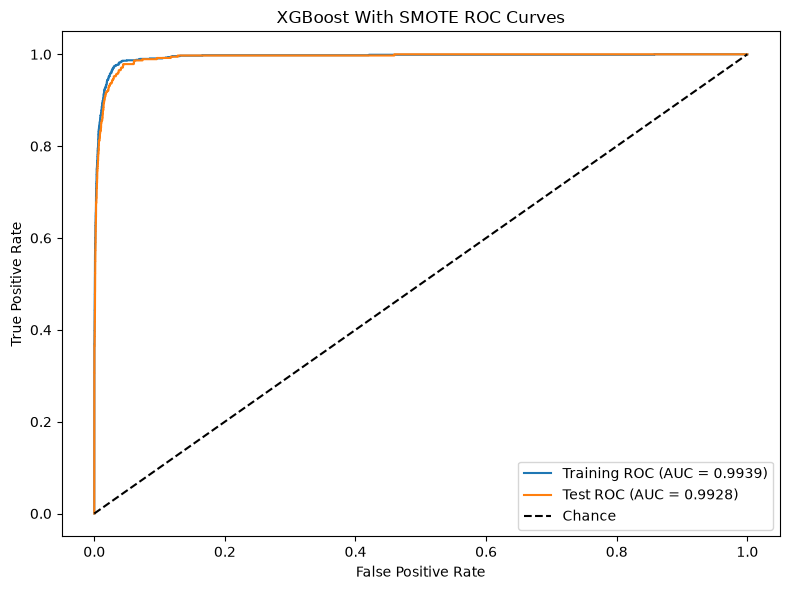

,XGBoost without SMOTE,XGBoost with SMOTE
Five-fold CV error,0.006983,0.022633
Test error,0.009125,0.023938
Test AUC,0.995915,0.992780
Test positive-class recall,0.682667,0.930667


In [11]:
smote_xgb_best = smote_search.best_estimator_

train_pred_smote = smote_xgb_best.predict(X_train)
test_pred_smote = smote_xgb_best.predict(X_test)

train_prob_smote = smote_xgb_best.predict_proba(X_train)[:, 1]
test_prob_smote = smote_xgb_best.predict_proba(X_test)[:, 1]

train_cm_smote = confusion_matrix(
    y_train_xgb, train_pred_smote, labels=[0, 1]
)
test_cm_smote = confusion_matrix(
    y_test_xgb, test_pred_smote, labels=[0, 1]
)

print("Training confusion matrix (rows = true, columns = predicted; 0 = neg, 1 = pos):")
print(train_cm_smote)

print("Test confusion matrix (rows = true, columns = predicted; 0 = neg, 1 = pos):")
print(test_cm_smote)

train_error_smote = np.mean(train_pred_smote != y_train_xgb)
test_error_smote = np.mean(test_pred_smote != y_test_xgb)

train_auc_smote = roc_auc_score(y_train_xgb, train_prob_smote)
test_auc_smote = roc_auc_score(y_test_xgb, test_prob_smote)

print(f"Best alpha with SMOTE: {best_alpha_smote}")
print(f"Five-fold CV error with SMOTE: {cv_error_smote:.4f}")
print(f"Training misclassification rate: {train_error_smote:.4f}")
print(f"Test misclassification rate: {test_error_smote:.4f}")
print(f"Training AUC: {train_auc_smote:.4f}")
print(f"Test AUC: {test_auc_smote:.4f}")

fpr_train_smote, tpr_train_smote, _ = roc_curve(
    y_train_xgb, train_prob_smote
)
fpr_test_smote, tpr_test_smote, _ = roc_curve(
    y_test_xgb, test_prob_smote
)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr_train_smote,
    tpr_train_smote,
    label=f"Training ROC (AUC = {train_auc_smote:.4f})"
)
plt.plot(
    fpr_test_smote,
    tpr_test_smote,
    label=f"Test ROC (AUC = {test_auc_smote:.4f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost With SMOTE ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

# Compare positive-class recall on the original test set
baseline_cm = confusion_matrix(
    y_test_xgb, test_pred_xgb, labels=[0, 1]
)
baseline_tn, baseline_fp, baseline_fn, baseline_tp = baseline_cm.ravel()
smote_tn, smote_fp, smote_fn, smote_tp = test_cm_smote.ravel()

baseline_recall = baseline_tp / (baseline_tp + baseline_fn)
smote_recall = smote_tp / (smote_tp + smote_fn)

smote_comparison = pd.DataFrame({
    "XGBoost without SMOTE": [
        cv_error,
        test_error_xgb,
        test_auc_xgb,
        baseline_recall
    ],
    "XGBoost with SMOTE": [
        cv_error_smote,
        test_error_smote,
        test_auc_smote,
        smote_recall
    ]
}, index=[
    "Five-fold CV error",
    "Test error",
    "Test AUC",
    "Test positive-class recall"
])

display(smote_comparison)

Five-fold stratified cross-validation selected alpha = 0, with a CV error of 0.0226. The test error was 0.0239. Compared with XGBoost without SMOTE, the test positive-class recall increased from 68.27% to 93.07%, and false negatives decreased from 119 to 26. However, false positives increased from 27 to 357, and the test AUC decreased slightly from 0.9959 to 0.9928. In this run, SMOTE improved detection of the minority class at the cost of more false positives and a higher overall test error.

## Question 2: ISLR 6.6.3

As the constraint parameter \(s\) increases, the set of coefficient values allowed by the Lasso constraint becomes larger. This makes the model more flexible.

(a) Training RSS — iv. Steadily decrease.
As \(s\) increases, the set of allowed coefficient values becomes larger. The model can fit the training data at least as well as before, so the training RSS cannot increase.

(b) Test RSS — ii. Decrease initially, then eventually increase in a U shape.
Increasing model flexibility initially reduces bias and improves test performance. If the model becomes too flexible, its variance increases and it may fit noise in the training data, causing test RSS to rise.

(c) Variance — iii. Steadily increase.
More flexible models are more sensitive to changes in the training data, so their variance increases.

(d) Squared bias — iv. Steadily decrease.
As the constraint is relaxed, the model can fit a wider range of patterns, so its squared bias decreases.

(e) Irreducible error — v. Remain constant.
Irreducible error is due to randomness in the response and does not depend on the model’s flexibility.

## Question 3: ISLR 6.6.5 — Submitted Separately

This problem is solved by hand and submitted as a separate document.

## Question 4: ISLR 8.4.5

Probability is greater than 0.5. Six of the ten estimates are greater
than 0.5, so the majority vote predicts Red.

For the average probability approach,

(0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75) / 10
= 4.5 / 10
= 0.45.

Since the average probability of Red is less than 0.5, this approach
predicts Green.

## Question 5: ISLR 9.7.3

In [12]:
import numpy as np
import matplotlib.pyplot as plt

red_points = np.array([
    [3, 4],
    [2, 2],
    [4, 4],
    [1, 4]
])

blue_points = np.array([
    [2, 1],
    [4, 3],
    [4, 1]
])

support_vectors = np.array([
    [2, 2],
    [4, 4],
    [2, 1],
    [4, 3]
])

### Part(a) Sketch the observations
The Red observations are (3, 4), (2, 2), (4, 4), and (1, 4).
The Blue observations are (2, 1), (4, 3), and (4, 1).

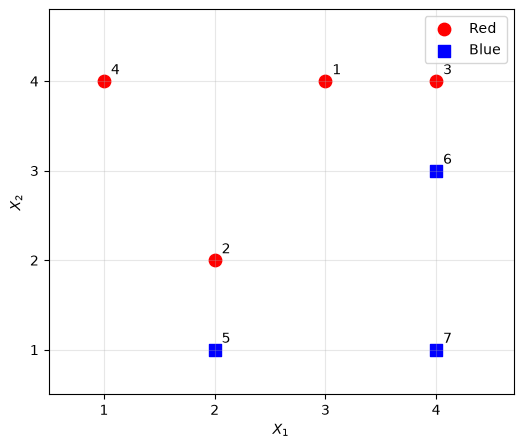

In [13]:
plt.figure(figsize=(6, 5))

plt.scatter(
    red_points[:, 0], red_points[:, 1],
    color="red", marker="o", s=80, label="Red"
)
plt.scatter(
    blue_points[:, 0], blue_points[:, 1],
    color="blue", marker="s", s=80, label="Blue"
)

for i, (x1, x2) in enumerate(red_points, start=1):
    plt.annotate(str(i), (x1, x2), xytext=(5, 5), textcoords="offset points")

for i, (x1, x2) in enumerate(blue_points, start=5):
    plt.annotate(str(i), (x1, x2), xytext=(5, 5), textcoords="offset points")

plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.xlim(0.5, 4.7)
plt.ylim(0.5, 4.8)
plt.xticks(range(1, 5))
plt.yticks(range(1, 5))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Part(b) Sketch the optimal separating hyperplane

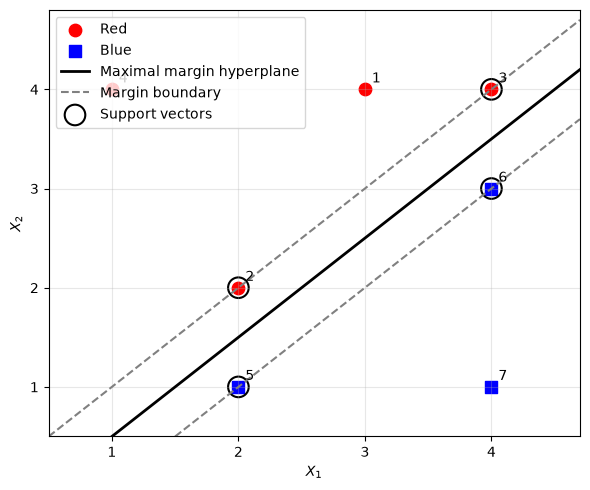

In [14]:
x1_line = np.linspace(0.5, 4.7, 200)

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    red_points[:, 0], red_points[:, 1],
    color="red", marker="o", s=80, label="Red"
)
ax.scatter(
    blue_points[:, 0], blue_points[:, 1],
    color="blue", marker="s", s=80, label="Blue"
)

for i, (x1, x2) in enumerate(red_points, start=1):
    ax.annotate(
        str(i), (x1, x2),
        xytext=(5, 5), textcoords="offset points"
    )

for i, (x1, x2) in enumerate(blue_points, start=5):
    ax.annotate(
        str(i), (x1, x2),
        xytext=(5, 5), textcoords="offset points"
    )

ax.plot(
    x1_line, x1_line - 0.5,
    color="black", linewidth=2,
    label="Maximal margin hyperplane"
)
ax.plot(
    x1_line, x1_line,
    color="gray", linestyle="--",
    label="Margin boundary"
)
ax.plot(
    x1_line, x1_line - 1,
    color="gray", linestyle="--"
)

ax.scatter(
    support_vectors[:, 0], support_vectors[:, 1],
    s=220, facecolors="none", edgecolors="black",
    linewidths=1.5, label="Support vectors"
)

ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_xlim(0.5, 4.7)
ax.set_ylim(0.5, 4.8)
ax.set_xticks(range(1, 5))
ax.set_yticks(range(1, 5))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Part(c) Classification rule and coefficients

Classify an observation as Red if

\[
0.5-X_1+X_2>0,
\]

and classify it as Blue otherwise. Therefore,

\[
\beta_0=0.5,\qquad \beta_1=-1,\qquad \beta_2=1.
\]

### Part(d) Indicate the margin

The two margin boundaries are \(X_2=X_1\) and \(X_2=X_1-1\). The support vectors lie on these boundaries. The distance between the two boundaries is \(1/\sqrt{2}\), so the distance from the separating hyperplane to either boundary is \(1/(2\sqrt{2})\).

### Part(e) Support vectors

The support vectors are observations 2 and 3 from the Red class,
and observations 5 and 6 from the Blue class.

### Part (f): Effect of Moving Observation 7

Observation 7 is not a support vector. The maximal margin hyperplane is determined by the support vectors, which are observations 2, 3, 5, and 6. Therefore, a small movement of observation 7 will not change the hyperplane, provided that it remains outside the margin.

### Part(g) Give a separating hyperplane that is not optimal

One separating hyperplane that is not the maximal margin hyperplane is

\[
X_2=X_1-0.25.
\]

Classify an observation as Red if \(X_2-X_1+0.25>0\), and as Blue otherwise. This line separates the two classes, but it does not maximize the margin.

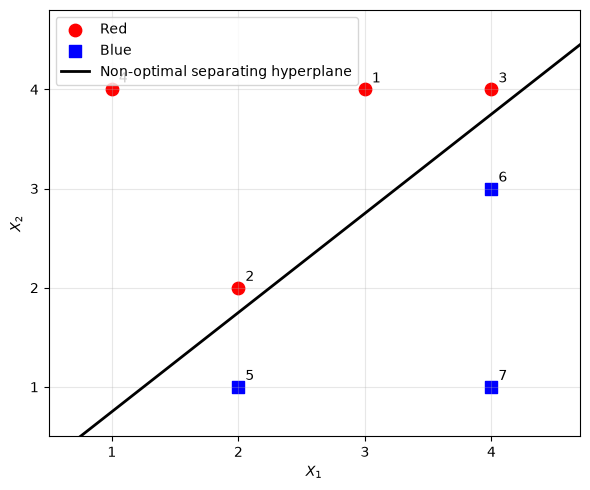

In [15]:
x1_line = np.linspace(0.5, 4.7, 200)

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    red_points[:, 0], red_points[:, 1],
    color="red", marker="o", s=80, label="Red"
)
ax.scatter(
    blue_points[:, 0], blue_points[:, 1],
    color="blue", marker="s", s=80, label="Blue"
)

for i, (x1, x2) in enumerate(red_points, start=1):
    ax.annotate(
        str(i), (x1, x2),
        xytext=(5, 5), textcoords="offset points"
    )

for i, (x1, x2) in enumerate(blue_points, start=5):
    ax.annotate(
        str(i), (x1, x2),
        xytext=(5, 5), textcoords="offset points"
    )

ax.plot(
    x1_line, x1_line - 0.25,
    color="black", linewidth=2,
    label="Non-optimal separating hyperplane"
)

ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_xlim(0.5, 4.7)
ax.set_ylim(0.5, 4.8)
ax.set_xticks(range(1, 5))
ax.set_yticks(range(1, 5))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Part(h) Add one observation so the classes are not linearly separable

Add a Blue observation at \((2,2)\), which is the location of Red observation 2. Since the same predictor values would then have opposite class labels, no hyperplane can separate all the observations correctly.

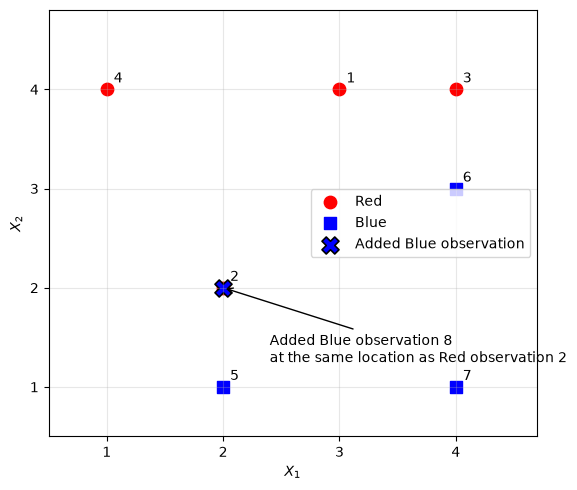

In [16]:
extra_blue = np.array([[2, 2]])
x1_line = np.linspace(0.5, 4.7, 200)

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    red_points[:, 0], red_points[:, 1],
    color="red", marker="o", s=80, label="Red"
)
ax.scatter(
    blue_points[:, 0], blue_points[:, 1],
    color="blue", marker="s", s=80, label="Blue"
)
ax.scatter(
    extra_blue[:, 0], extra_blue[:, 1],
    color="blue", marker="X", s=150,
    edgecolors="black", linewidths=1.2,
    label="Added Blue observation"
)

for i, (x1, x2) in enumerate(red_points, start=1):
    ax.annotate(
        str(i), (x1, x2),
        xytext=(5, 5), textcoords="offset points"
    )

for i, (x1, x2) in enumerate(blue_points, start=5):
    ax.annotate(
        str(i), (x1, x2),
        xytext=(5, 5), textcoords="offset points"
    )

ax.annotate(
    "Added Blue observation 8\nat the same location as Red observation 2",
    xy=(2, 2),
    xytext=(2.4, 1.25),
    arrowprops={"arrowstyle": "->"}
)

ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_xlim(0.5, 4.7)
ax.set_ylim(0.5, 4.8)
ax.set_xticks(range(1, 5))
ax.set_yticks(range(1, 5))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()